# 02 — Baseline: Savaşı sayılara çevirmek

**Hedef:** Her savaşı tek satırlık bir sayı listesine çevirmek → model → 5-fold CV → submission.

Özellik kodu `src/features_v1.py` içinde (teslimde GitHub'dan klonlanacak modül). Bu notebook onu kullanıyor ve her özelliği **savaş 0** üzerinde gösteriyor.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from src.features_v1 import build_features, last_known_state

train = pd.read_json("data/train.jsonl", lines=True)
test = pd.read_json("data/test.jsonl", lines=True)

## 1. Fikir: 30. turda "skor tablosu" ne?

Savaş 0'ı hatırla. Her Pokémon'un **timeline'da son görüldüğü** durumu alırsak, 30. turdaki tabloyu çıkarırız.
`last_known_state` fonksiyonu bunu yapıyor:

In [2]:
b0 = train.iloc[0]
for side in ["p1", "p2"]:
    last = last_known_state(b0.battle_timeline, side)
    print(side.upper())
    display(pd.DataFrame([{"name": n, "hp": s["hp_pct"], "status": s["status"]} for n, s in last.items()]))

P1


,name,hp,status
0,tyranitar,0.00,fnt
1,typhlosion,1.00,slp
2,golem,0.76,nostatus
3,umbreon,0.92,nostatus
4,alakazam,1.00,nostatus


P2


,name,hp,status
0,forretress,0.85,nostatus
1,zapdos,1.00,slp
2,snorlax,0.82,slp
3,piloswine,1.00,nostatus
4,skarmory,1.00,nostatus


- P1: Raikou hiç sahaya çıkmadı → tabloda yok, **tam can varsayıyoruz**.
- P2: 5 Pokémon görüldü, 6.'sı bilinmiyor → o da **tam can varsayılıyor**.

Buradan çıkan özellikler: `seen`, `fainted`, `hp_total`, `n_slp`, `n_par`, ... (her oyuncu için).

## 2. Tüm özellikler

| Grup | Özellik (her oyuncu için `p1_` / `p2_` ön ekli) | Anlamı |
|---|---|---|
| Takım durumu | `seen` | sahaya çıkan farklı Pokémon sayısı |
| | `fainted` | bayılan sayısı |
| | `hp_total` | 6 Pokémon'un toplam kalan canı (0–6) |
| | `n_slp, n_par, n_frz, n_tox, n_psn, n_brn` | o status'taki Pokémon sayısı |
| Sahadaki Pokémon (30. tur) | `active_hp` | canı |
| | `active_boost_sum`, `active_boost_atk`... | stat güçlendirmeleri (Curse, Swords Dance) |
| Davranış | `switches` | kaç kere Pokémon değiştirdi |
| | `no_move_turns` | hamle yapamadığı/yapmadığı tur |
| | `status_moves` | hasarsız hamle sayısı (toxic, rest, curse...) |
| | `avg_base_power` | hamlelerin ortalama gücü |
| | `damage_dealt` | rakibe verdiği toplam hasar (HP düşüşü) |
| Farklar (P1 lehine +) | `diff_hp_total, diff_fainted, diff_damage_dealt, diff_disabled`... | iki tarafın karşılaştırması |

In [3]:
X = build_features(train)
y = train.set_index("battle_id").loc[X.index, "player_won"]
X_test = build_features(test)

print("X:", X.shape, " X_test:", X_test.shape)
X.loc[0].to_frame("savaş 0").T

X: (10000, 49)  X_test: (5000, 49)


,p1_seen,p1_fainted,p1_hp_total,p1_n_slp,p1_n_par,p1_n_frz,p1_n_tox,p1_n_psn,p1_n_brn,p1_active_hp,...,p2_status_moves,p2_avg_base_power,p2_damage_dealt,diff_hp_total,diff_active_hp,diff_active_boost_sum,diff_damage_dealt,diff_seen,diff_fainted,diff_disabled
savaş 0,5.0,1.0,4.68,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,18.0,24.615385,3.22,-0.99,0.15,0.0,-1.8,0.0,-1.0,1.0


**Kontrol:** savaş 0 hikayesiyle uyuşuyor mu? P1'de 1 bayılan (Tyranitar), P2'de 0, P2'den 5 Pokémon görüldü → `diff_fainted = -1`, `p2_seen = 5`.

## 3. Her özellik tek başına ne kadar bilgi taşıyor?
Korelasyon (`player_won` ile). + ise yüksek değer P1'in kazanmasıyla ilişkili.

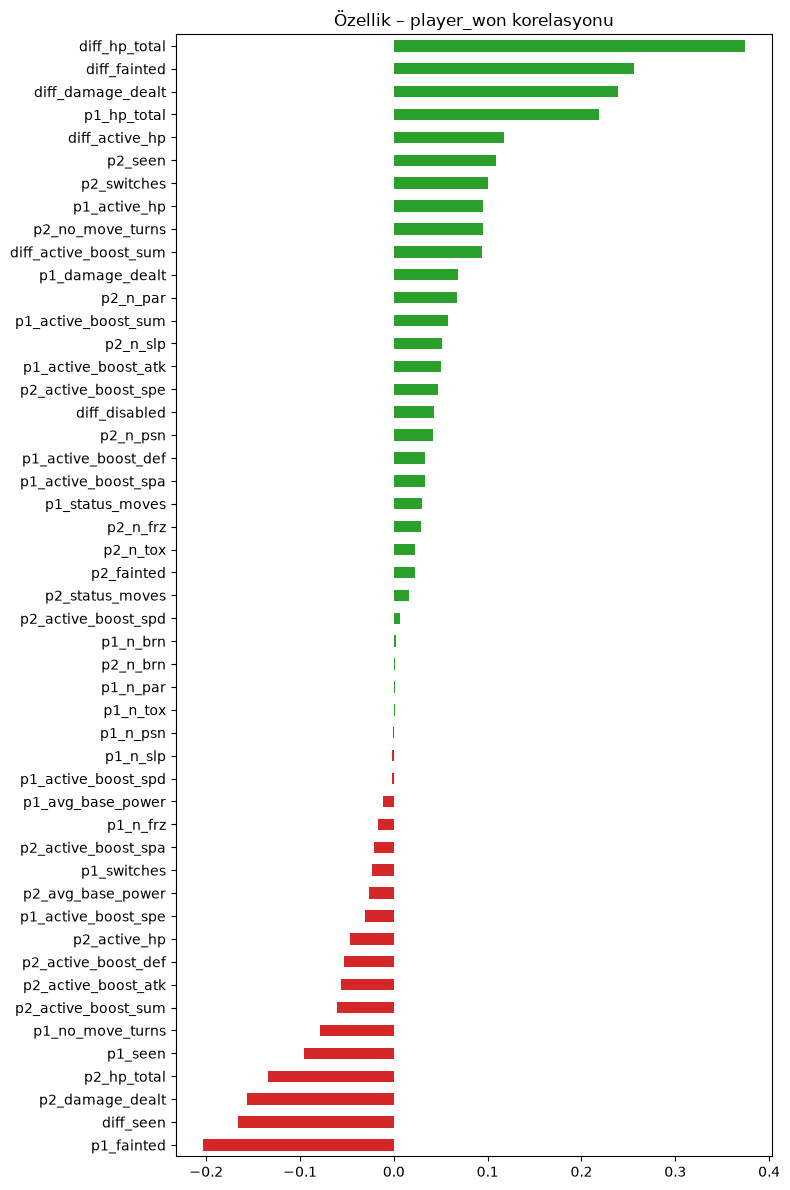

In [4]:
corr = X.corrwith(y).sort_values()
fig, ax = plt.subplots(figsize=(8, 12))
corr.plot.barh(ax=ax, color=np.where(corr > 0, "tab:green", "tab:red"))
ax.set_title("Özellik – player_won korelasyonu"); plt.tight_layout(); plt.show()

## 4. Validation: 5-fold Cross Validation

Train'i 5 parçaya böl → 4'üyle eğit, 1'iyle test et → 5 kere tekrarla → ortalama doğruluk.
**Bütün kararları bu skora göre vereceğiz.** (Test seti sadece en sonda tahmin için.)

In [5]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "LogisticRegression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "RandomForest": RandomForestClassifier(n_estimators=500, min_samples_leaf=5, n_jobs=-1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, random_state=42),
}

results = {}
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    results[name] = scores
    print(f"{name:22s} {scores.mean():.4f} ± {scores.std():.4f}")

LogisticRegression     0.6692 ± 0.0060


RandomForest           0.6708 ± 0.0095


HistGradientBoosting   0.6647 ± 0.0106


## 5. Model neye bakıyor? (Logistic Regression katsayıları)
Özellikler standardize edildiği için katsayılar karşılaştırılabilir: büyüklük = önem, işaret = yön.

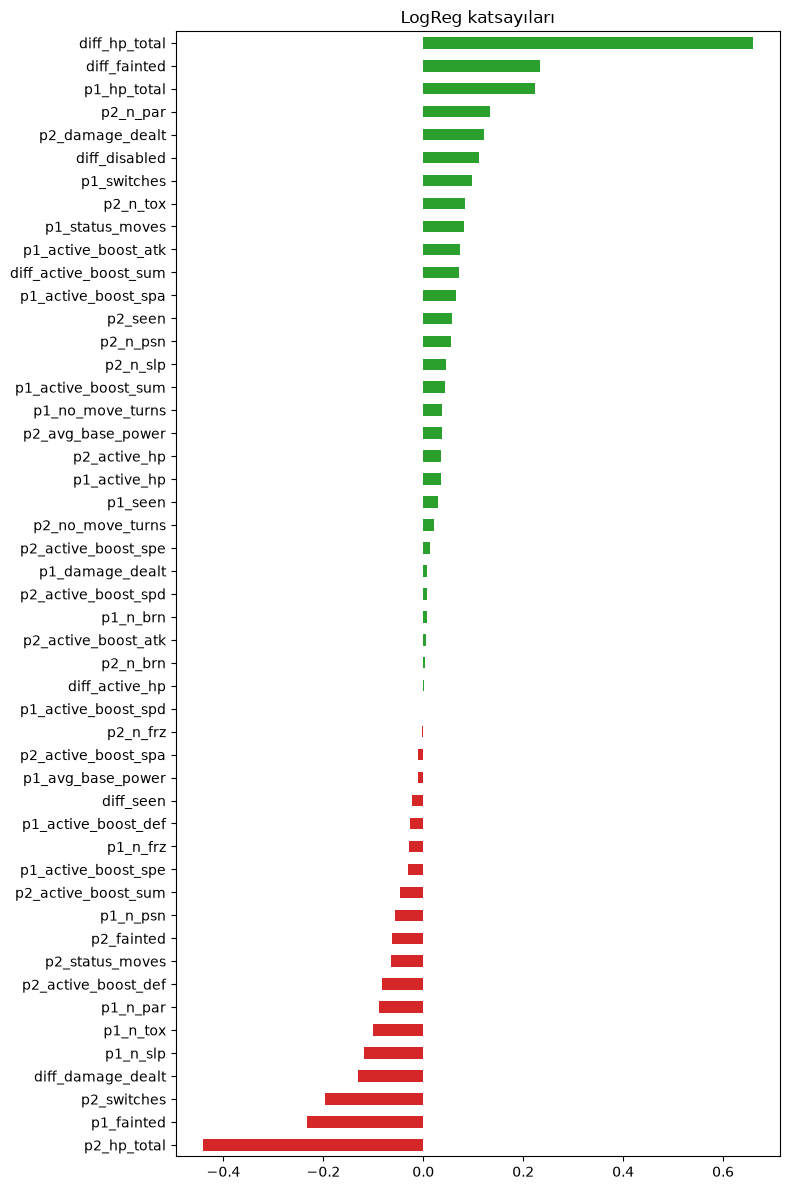

In [6]:
lr = models["LogisticRegression"].fit(X, y)
coef = pd.Series(lr[-1].coef_[0], index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(8, 12))
coef.plot.barh(ax=ax, color=np.where(coef > 0, "tab:green", "tab:red"))
ax.set_title("LogReg katsayıları"); plt.tight_layout(); plt.show()

## 6. Hata analizi — yeni fikirlerin kaynağı
Modelin **en emin olduğu halde yanıldığı** savaşlar. Bunlara `show_battle` ile bakıp "neden?" diye sor.

In [7]:
from sklearn.model_selection import cross_val_predict

proba = cross_val_predict(models["LogisticRegression"], X, y, cv=cv, method="predict_proba")[:, 1]
err = pd.DataFrame({"p1_win_proba": proba, "player_won": y})
err["wrong"] = (err.p1_win_proba > 0.5) != err.player_won
err["confidence"] = (err.p1_win_proba - 0.5).abs()
confident_wrong = err[err.wrong].sort_values("confidence", ascending=False)
confident_wrong.head(10).join(X[["diff_fainted", "diff_hp_total", "p2_seen"]])

,p1_win_proba,player_won,wrong,confidence,diff_fainted,diff_hp_total,p2_seen
battle_id,,,,,,,
7989,0.028415,1,True,0.471585,-5,-3.117870,5
7242,0.042982,1,True,0.457018,-4,-3.187429,6
680,0.948882,0,True,0.448882,0,3.290000,5
1636,0.054765,1,True,0.445235,-4,-3.380000,6
3267,0.057033,1,True,0.442967,-3,-3.000000,4
8070,0.942318,0,True,0.442318,-2,0.950000,6
3969,0.061798,1,True,0.438202,-5,-3.860378,6
1861,0.063090,1,True,0.436910,-5,-3.520000,5
6781,0.063175,1,True,0.436825,-4,-3.650000,5


In [8]:
def show_battle(bid, df=train):
    tl = df.set_index("battle_id").loc[bid, "battle_timeline"]
    rows = []
    for t in tl:
        a, b = t["p1_pokemon_state"], t["p2_pokemon_state"]
        rows.append({"turn": t["turn"],
                     "p1": a["name"], "p1_hp": a["hp_pct"], "p1_status": a["status"],
                     "p1_move": t["p1_move_details"]["name"] if t["p1_move_details"] else "—",
                     "p2": b["name"], "p2_hp": b["hp_pct"], "p2_status": b["status"],
                     "p2_move": t["p2_move_details"]["name"] if t["p2_move_details"] else "—"})
    return pd.DataFrame(rows).set_index("turn")

worst = confident_wrong.index[0]
print("battle_id:", worst, " model P1 kazanma olasılığı:", round(err.loc[worst, "p1_win_proba"], 3), " gerçek:", y[worst])
show_battle(worst)

battle_id: 7989  model P1 kazanma olasılığı: 0.028  gerçek: 1


,p1,p1_hp,p1_status,p1_move,p2,p2_hp,p2_status,p2_move
turn,,,,,,,,
1,forretress,0.592068,nostatus,toxic,marowak,1.000000,tox,earthquake
2,forretress,0.654391,nostatus,spikes,marowak,0.938080,tox,swordsdance
3,forretress,0.000000,fnt,spikes,marowak,0.938080,tox,earthquake
4,starmie,1.000000,nostatus,—,marowak,0.938080,tox,earthquake
5,starmie,1.000000,nostatus,hydropump,starmie,0.938080,nostatus,—
6,starmie,1.000000,nostatus,thunderbolt,starmie,0.452012,nostatus,rapidspin
7,starmie,1.000000,nostatus,thunderbolt,dragonite,0.859740,nostatus,—
8,starmie,1.000000,par,icebeam,dragonite,0.088312,nostatus,thunderwave
9,starmie,1.000000,par,thunderbolt,dragonite,0.877922,slp,rest


## 7. Submission
En iyi CV skorlu modeli tüm train'le eğitip test için tahmin.

In [9]:
best_name = max(results, key=lambda k: results[k].mean())
best = models[best_name].fit(X, y)
sub = pd.DataFrame({"battle_id": X_test.index, "player_won": best.predict(X_test).astype(int)})
sub.to_csv("submission_baseline.csv", index=False)
print("Model:", best_name, " CV:", round(results[best_name].mean(), 4))
print(sub.player_won.value_counts(normalize=True))
sub.head()

Model: RandomForest  CV: 0.6708
player_won
1    0.5148
0    0.4852
Name: proportion, dtype: float64


,battle_id,player_won
0,0,1
1,1,0
2,2,0
3,3,0
4,4,1


## Sonraki adımlar (her biri ayrı deney → CV skoru not edilecek)
1. Hata analizi tablosundaki savaşlara bak → yeni özellik fikri.
2. Tip avantajı (süper etkili vuruş sayısı, tip tablosuyla).
3. Gidişat: turn 10 / 20 / 30'daki farklar, son 10 turdaki hasar.
4. Takım kompozisyonu: P1 multi-hot, P2'de görülen Pokémon'lar.
5. Model: LightGBM/XGBoost + hiperparametre ayarı → ensemble.